# Игрок против профиля своего рейтингового бина (Cache, Premier)

Ноутбук 2 из 2. Берём **обычного** игрока (не рекордсмена по объёму данных), относим его к одному из 5 рейтинговых бинов
из `notebooks/rating_cohort_analysis.ipynb` и сравниваем его утилити с профилем этого бина.

## Содержание

Коротко: типичный игрок против профиля своего рейтингового бина, с честной оценкой неточности.

1. **Введение и цель** — сравнить игрока с профилем бина; скромнее, чем `player_utility_analysis.ipynb`.
2. **Ограничения** — только утилити, мало матчей, слабое разделение бинов: бин — грубая оценка.
3. **Загрузка профилей бинов и данных** — `rating_bin_profiles.parquet`, parquet-кэш, те же признаки, что в ноутбуке 1.
4. **Выбор игрока** — типичный игрок у медианы по матчам и броскам, его базовая статистика.
5. **Присвоение бина** — бин по рейтингу и независимая поведенческая оценка, их сравнение и проверка точности.
6. **Профиль игрока vs бин** — 17 признаков игрока против центроида бина в единицах внутрибинового std.
7. **Разбор по типам утилити** — микс, флешки, HE, молотовы относительно бина, с пометками малой выборки.
8. **Тайминг бросков по раунду** — время бросков игрока против `t_in_round_*` бина.
9. **Выводы для игрока** — правила рекомендаций и итог для аналитика, в конце — отчёт для игрока простым языком с инструментами SCOPE.GG.

## 1. Введение и цель

**Цель:** показать, как выглядит персональный отчёт «ты против своего рейтингового бина» для **рядового** пользователя SCOPE.GG.

В `player_utility_analysis.ipynb` мы брали игрока с максимумом данных в датасете (9 матчей, 310 гранат). Это нетипично:
у большинства игроков в датасете 1 матч, а среди тех, у кого их больше одного, медиана — 2 матча и ~50 гранат.
Здесь берём именно такой средний случай, чтобы увидеть, что реально можно сказать по такому объёму.

Как устроено сравнение:
- **профили бинов** (центроид, std и N по 17 признакам для 5 квантильных бинов рейтинга) берём из
  `data/processed/rating_bin_profiles.parquet`, который построил ноутбук 1;
- признаки игрока считаем **тем же кодом** (те же формулы, тот же порог `MIN_N = 3`) и **усредняем по всем его матчам**;
- бин определяем двумя независимыми способами: по рейтингу (если он известен) и по поведению (взвешенный ближайший центроид),
  и честно сравниваем их.

**Главное, что надо знать заранее: бин, определённый по поведению, — грубая и шумная оценка.** По утилити рейтинговые бины
почти не различаются (ноутбук 1, раздел 10): заметно разделяет только `nades_per_round` (размах B1–B5 ≈ 0.6 внутрибинового std),
остальные 16 признаков — меньше 0.3. На проверке (раздел 5.3) поведенческая оценка угадывает точный бин примерно в 26% случаев
при случайных 20%. Поэтому для игрока с рейтингом бин берём по рейтингу, а поведенческую оценку показываем только как ориентир.

См. также: `docs/poc_findings_summary.md` — сводка этого вывода для всего POC.

## 2. Ограничения

- **Только утилити.** Нет стрельбы и аима, движения вне моментов броска, экономики (денег, закупа), смертей не от гранат
  и исходов раундов. Рейтинг зависит от всего этого, а мы видим только гранаты. «Мало гранат» может значить «не было денег».
- **Рейтинг известен только у 24.4% игроков-матчей.** Профили бинов построены по этой четверти; игроки с рейтингом — не случайная
  выборка (Premier, открытые профили), профили могут не переноситься один в один на игроков без рейтинга.
- **Урон HE и огня по своим не записан** (`DamagedPlayers` содержит только врагов). «Тимдамаг» оцениваем только по флешкам.
- **Нет начала раунда.** Тайминг считаем от первой гранаты раунда (любого игрока) — это прокси.
- **Маленькая выборка.** У выбранного игрока 2 матча и несколько десятков бросков; по отдельным типам гранат — единицы.
  Метрику по типу за матч считаем только при **≥ 3 бросках** этого типа (как в ноутбуке 1), и везде помечаем, где данных мало.
- **Корреляция, а не причинность.** «В бине B5 больше урона HE» не значит, что урон HE поднимает рейтинг.
- **Новое и главное для этого ноутбука: бины слабо различаются по утилити.** В ноутбуке 1 (раздел 10) размах центроидов B1–B5
  у лучшего признака (гранаты за раунд) — около 0.6 внутрибинового std, у остальных — 0.3 и меньше, у долей микса и тайминга смоков —
  меньше 0.1. Распределения бинов почти полностью перекрываются. Поэтому **любое отнесение к бину по утилити — грубая оценка, а не вердикт**,
  особенно для игрока без рейтинга. В разделе 5.3 мы проверяем, насколько часто такая оценка вообще угадывает бин.

## 3. Загрузка профилей бинов и данных

Те же константы и стиль, что в `eda.ipynb` и ноутбуке 1. Читаем готовый parquet-кэш из `data/processed/`
(его строит `flatten()` в `eda.ipynb`); исходный pickle здесь не нужен.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 90
plt.rcParams['figure.figsize'] = (10, 4.5)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

CACHE_DIR = '../data/processed'
PROFILE_PATH = os.path.join(CACHE_DIR, 'rating_bin_profiles.parquet')
TICKRATE = 64  # проверено в eda.ipynb: фитиль HE/флешки = 104 тика = 1.625 с
GT_ORDER = ['smoke', 'flash', 'he', 'molotov']
GT_COLORS = {'smoke': '#7f7f7f', 'flash': '#e5ae38', 'he': '#2ca02c', 'molotov': '#d62728'}
KEY = ['match_id', 'thrower_id']
PLAYER_COLOR = '#c44e52'
LOW_N_THROWS = 20  # меньше 20 бросков типа за все матчи игрока — помечаем «мало данных» (обоснование в разделе 6)

### 3.1 Профили бинов

Схема файла описана в разделе 11 ноутбука 1: одна строка на бин; для каждого из 17 признаков — центроид `<feature>`,
внутрибиновое std `<feature>_std` и число пар «игрок–матч» `<feature>_n`, прошедших порог `min_n`.
Список признаков берём из самого файла, а не задаём руками.

In [2]:
prof = pd.read_parquet(PROFILE_PATH).sort_values('bin').set_index('bin')
FEATURES = [c for c in prof.columns if f'{c}_std' in prof.columns and f'{c}_n' in prof.columns]
MIN_N = int(prof['min_n'].iloc[0])
N_BINS = len(prof)
BIN_LABELS = prof['bin_label'].tolist()
BIN_PALETTE = dict(zip(prof.index, sns.color_palette('viridis', N_BINS)))

CENTROIDS = prof[FEATURES]                                    # бин × признак
BIN_STD = prof[[f'{f}_std' for f in FEATURES]].set_axis(FEATURES, axis=1)
BIN_N = prof[[f'{f}_n' for f in FEATURES]].set_axis(FEATURES, axis=1)
BIN_CI = 1.96 * BIN_STD / np.sqrt(BIN_N)  # ±95% ДИ среднего бина: точность центроида, а не разброс игроков (это BIN_STD)

print(f'Бинов: {N_BINS}, признаков: {len(FEATURES)}, MIN_N = {MIN_N}')
print('Признаки:', FEATURES)
prof[['bin_label', 'rating_lo', 'rating_hi', 'n_player_matches']]

Бинов: 5, признаков: 17, MIN_N = 3
Признаки: ['nades_per_round', 'share_smoke', 'share_flash', 'share_he', 'share_molotov', 'flash_enemies_per_flash', 'flash_team_per_flash', 'flash_empty_share', 'flash_kills_per100', 'he_dmg_per_throw', 'he_zero_share', 'molotov_dmg_per_throw', 'molotov_zero_share', 't_in_round_smoke', 't_in_round_flash', 't_in_round_he', 't_in_round_molotov']


,bin_label,rating_lo,rating_hi,n_player_matches
bin,,,,
1,"B1: 1,000–8,567","1,000.000","8,567.000",4880
2,"B2: 8,567–13,077","8,567.000","13,076.800",4877
3,"B3: 13,077–16,411","13,076.800","16,411.200",4879
4,"B4: 16,411–19,999","16,411.200","19,999.000",5011
5,"B5: 19,999–30,982","19,999.000","30,982.000",4746


In [3]:
throws, damage, flashed, players = (pd.read_parquet(os.path.join(CACHE_DIR, f'{n}.parquet'))
                                    for n in ['throws', 'damage', 'flashed', 'players'])
for name, df in [('throws', throws), ('damage', damage), ('flashed', flashed), ('players', players)]:
    print(f'{name:8s} {df.shape[0]:>10,} строк × {df.shape[1]:>2} колонок')

throws    2,385,417 строк × 30 колонок
damage      344,524 строк × 11 колонок
flashed   1,001,026 строк × 14 колонок
players      99,921 строк ×  3 колонок


### 3.2 Производные признаки на уровне броска

Копия раздела 3.1 ноутбука 1 без изменений: урон HE/огня по врагам (HP + броня), число ослеплённых врагов и тиммейтов на флешку,
`flash_kills`, `t_in_round` (секунды от первой гранаты раунда) и `rounds_in_match` (макс. раунд с гранатой + 1).

In [4]:
meta = throws[['team', 'thrower_id']]
damage = damage.join(meta, on='throw_idx')
flashed = flashed.join(meta, on='throw_idx')
for df in (damage, flashed):
    df['rel'] = np.select([df['victim_id'] == df['thrower_id'], df['victim_team'] == df['team']],
                          ['self', 'team'], 'enemy')

# HE / огонь: DamagedPlayers содержит только врагов
en = damage[damage['rel'] == 'enemy'].groupby('throw_idx').agg(
    enemy_dmg=('health_dmg', 'sum'), enemy_armor_dmg=('armor_dmg', 'sum'))
# флешки: сколько ослеплено врагов / тиммейтов, убийства ослеплённых врагов
fl_n = flashed.groupby(['throw_idx', 'rel']).size().unstack(fill_value=0)
fl_n = fl_n.reindex(columns=['enemy', 'team'], fill_value=0).add_prefix('n_flashed_')
fl_k = flashed[flashed['rel'] == 'enemy'].groupby('throw_idx').agg(flash_kills=('killed', 'sum'))
throws = throws.join(en).join(fl_n).join(fl_k)

is_dmg = throws['grenade_type'].isin(['he', 'molotov'])
is_fl = throws['grenade_type'] == 'flash'
for c in ['enemy_dmg', 'enemy_armor_dmg']:
    throws[c] = throws[c].where(~is_dmg, throws[c].fillna(0)).astype('float32')
for c in ['n_flashed_enemy', 'n_flashed_team', 'flash_kills']:
    throws[c] = throws[c].where(~is_fl, throws[c].fillna(0)).astype('float32')
throws['dmg_total'] = throws['enemy_dmg'] + throws['enemy_armor_dmg']

round_t0 = throws.groupby(['match_id', 'round'])['start_tick'].transform('min')
throws['t_in_round'] = (throws['start_tick'] - round_t0) / TICKRATE
rounds_in_match = throws.groupby('match_id')['round'].max() + 1

### 3.3 17 признаков на пару «игрок–матч»

Те же формулы, что в разделах 4–8 ноутбука 1, но для **всех** пар «игрок–матч» из `Players` (а не только с рейтингом):
признаки нужны и нашему игроку, и для проверки точности в разделе 5.3.
- `nades_per_round` — всего гранат / раундов в матче (пары без бросков дают 0);
- доли микса — при ≥ `MIN_N` бросках любых типов за матч;
- флешки, HE, молотов, тайминг — при ≥ `MIN_N` бросках этого типа за матч, иначе NaN.
  Пустая флешка = **не ослепила ни одного врага**.

**Проверка согласованности:** по парам с рейтингом пересчитываем центроиды бинов (границы — из файла профилей)
и сравниваем с файлом. Расхождение должно быть нулевым — значит, признаки игрока посчитаны так же, как профили.

In [5]:
MIX_FEATS = [f'share_{g}' for g in GT_ORDER]
FLASH_FEATS = ['flash_enemies_per_flash', 'flash_team_per_flash', 'flash_empty_share', 'flash_kills_per100']
HE_FEATS = ['he_dmg_per_throw', 'he_zero_share']
MOLOTOV_FEATS = ['molotov_dmg_per_throw', 'molotov_zero_share']
TIMING_FEATS = [f't_in_round_{g}' for g in GT_ORDER]
assert ['nades_per_round'] + MIX_FEATS + FLASH_FEATS + HE_FEATS + MOLOTOV_FEATS + TIMING_FEATS == FEATURES

pairs = players.drop_duplicates(['match_id', 'player_id']).rename(columns={'player_id': 'thrower_id'})
pm = pairs.set_index(KEY)[['rating']]
cnt = (throws.groupby(KEY + ['grenade_type']).size().unstack(fill_value=0)
       .reindex(columns=GT_ORDER, fill_value=0).add_prefix('n_'))
pm = pm.join(cnt)
pm[cnt.columns] = pm[cnt.columns].fillna(0)
pm['n_total'] = pm[cnt.columns].sum(axis=1)
pm['rounds'] = rounds_in_match.reindex(pm.index.get_level_values('match_id')).values
pm['nades_per_round'] = pm['n_total'] / pm['rounds']
for g in GT_ORDER:
    pm[f'share_{g}'] = (pm[f'n_{g}'] / pm['n_total']).where(pm['n_total'] >= MIN_N)

fb = throws[throws['grenade_type'] == 'flash'].assign(empty=lambda d: d['n_flashed_enemy'] == 0,
                                                       kills100=lambda d: 100 * d['flash_kills'])
fl_pm = fb.groupby(KEY).agg(flash_enemies_per_flash=('n_flashed_enemy', 'mean'), flash_team_per_flash=('n_flashed_team', 'mean'),
                            flash_empty_share=('empty', 'mean'), flash_kills_per100=('kills100', 'mean'))
pm = pm.join(fl_pm)
pm[FLASH_FEATS] = pm[FLASH_FEATS].where(pm['n_flash'] >= MIN_N)

for gt, feats in [('he', HE_FEATS), ('molotov', MOLOTOV_FEATS)]:
    d_pm = (throws[throws['grenade_type'] == gt].assign(zero=lambda d: d['dmg_total'] == 0)
            .groupby(KEY).agg(**{feats[0]: ('dmg_total', 'mean'), feats[1]: ('zero', 'mean')}))
    pm = pm.join(d_pm)
    pm[feats] = pm[feats].where(pm[f'n_{gt}'] >= MIN_N)

t_pm = throws.groupby(KEY + ['grenade_type'])['t_in_round'].mean().unstack().reindex(columns=GT_ORDER).add_prefix('t_in_round_')
pm = pm.join(t_pm)
for g in GT_ORDER:
    pm[f't_in_round_{g}'] = pm[f't_in_round_{g}'].where(pm[f'n_{g}'] >= MIN_N)

# проверка: центроиды по парам с рейтингом против файла профилей
BIN_EDGES = np.r_[prof['rating_lo'].iloc[0], prof['rating_hi'].values]
rated_pm = pm.dropna(subset=['rating'])
chk = rated_pm.groupby(pd.cut(rated_pm['rating'], BIN_EDGES, labels=prof.index, include_lowest=True), observed=True)[FEATURES].mean()
print(f'Пар «игрок–матч»: {len(pm):,}; с рейтингом: {len(rated_pm):,}')
print(f'Макс. |расхождение| центроидов с файлом профилей: {(chk - CENTROIDS).abs().max().max():.2e}')

Пар «игрок–матч»: 99,921; с рейтингом: 24,393
Макс. |расхождение| центроидов с файлом профилей: 0.00e+00


## 4. Выбор игрока

В отличие от `player_utility_analysis.ipynb` (максимум бросков среди игроков с ≥ 8 матчами), здесь нужен **типичный** случай.
Правило:
1. берём игроков, которые встречаются в `Players` **хотя бы в 2 матчах** (иначе усреднять нечего);
2. среди них — тех, у кого число матчей и общее число бросков ближе всего к **медианам** этой группы
   (расстояние в перцентильных рангах, чтобы матчи и броски весили одинаково);
3. при равенстве предпочитаем игрока, у которого рейтинг известен в большем числе матчей: тогда можно сравнить
   бин по рейтингу с поведенческой оценкой. Дальше — по `player_id`, чтобы выбор был воспроизводимым.

Код ниже не предполагает, что у игрока есть рейтинг: если его нет, раздел 5 пойдёт только по поведенческой ветке.

In [6]:
per_player = pairs.groupby('thrower_id').agg(matches=('match_id', 'nunique'), rated_matches=('rating', 'count'))
per_player['throws'] = throws.groupby('thrower_id').size().reindex(per_player.index).fillna(0).astype(int)
multi = per_player[per_player['matches'] >= 2].copy()

pct = multi[['matches', 'throws']].rank(pct=True)  # перцентильные ранги (одинаковые значения — средний ранг)
med = multi[['matches', 'throws']].median()
med_pct = pd.Series({c: pct.loc[(multi[c] - med[c]).abs().idxmin(), c] for c in med.index})  # ранг медианного значения
multi['dist_to_median'] = np.sqrt(((pct - med_pct) ** 2).sum(axis=1))
cand = multi.reset_index().sort_values(['dist_to_median', 'rated_matches', 'thrower_id'], ascending=[True, False, True])
PLAYER_ID = int(cand['thrower_id'].iloc[0])
me_row = multi.loc[PLAYER_ID]

print(f'Игроков всего: {len(per_player):,}; в ≥2 матчах: {len(multi):,} ({len(multi) / len(per_player):.1%})')
print('Матчей на игрока (≥2), распределение:', multi['matches'].value_counts().sort_index().to_dict())
print(f"Медианы в группе ≥2 матчей: матчей {multi['matches'].median():.0f}, бросков {multi['throws'].median():.0f}")
n_tied = (multi['dist_to_median'] == multi['dist_to_median'].min()).sum()
print(f'Кандидатов ровно на медиане: {n_tied}, из них с рейтингом хотя бы в одном матче: '
      f"{(multi.loc[multi['dist_to_median'] == multi['dist_to_median'].min(), 'rated_matches'] > 0).sum()}")
print(f"\nВыбран игрок {PLAYER_ID}: матчей {me_row['matches']:.0f}, бросков {me_row['throws']:.0f}, "
      f"рейтинг известен в {me_row['rated_matches']:.0f} матчах")
# перцентиль как диапазон: доля игроков группы строго меньше … меньше или равно (у одинаковых значений перцентиль — интервал)
for c, name in [('matches', 'числу матчей'), ('throws', 'числу бросков')]:
    print(f"  перцентиль по {name} среди игроков с ≥2 матчами: {(multi[c] < me_row[c]).mean():.0%}–{(multi[c] <= me_row[c]).mean():.0%}")

Игроков всего: 90,829; в ≥2 матчах: 6,937 (7.6%)
Матчей на игрока (≥2), распределение: {2: 5493, 3: 1004, 4: 275, 5: 105, 6: 33, 7: 17, 8: 2, 9: 7, 10: 1}
Медианы в группе ≥2 матчей: матчей 2, бросков 53
Кандидатов ровно на медиане: 82, из них с рейтингом хотя бы в одном матче: 41

Выбран игрок 25130446: матчей 2, бросков 53, рейтинг известен в 2 матчах
  перцентиль по числу матчей среди игроков с ≥2 матчами: 0%–79%
  перцентиль по числу бросков среди игроков с ≥2 матчами: 50%–51%


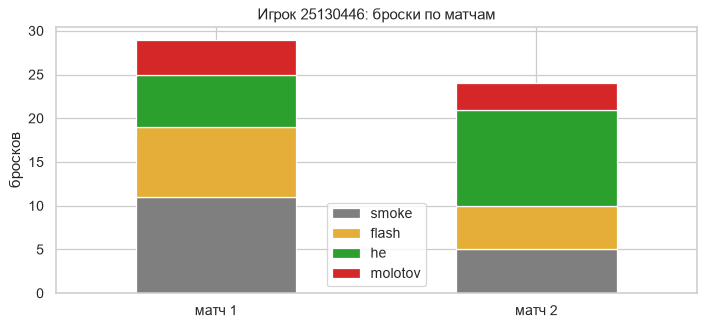

,smoke,flash,he,molotov,всего,раундов,гранат/раунд,рейтинг
матч 1,11.000,8.000,6.000,4.000,29.000,16.000,1.812,"16,125.000"
матч 2,5.000,5.000,11.000,3.000,24.000,15.000,1.600,"15,836.000"
итого,16.000,13.000,17.000,7.000,53.000,31.000,1.710,"15,980.500"


In [7]:
me_pm = pm.xs(PLAYER_ID, level='thrower_id')
me_throws = throws[throws['thrower_id'] == PLAYER_ID]

by_match = me_pm[[f'n_{g}' for g in GT_ORDER] + ['n_total', 'rounds', 'nades_per_round', 'rating']].copy()
by_match.columns = GT_ORDER + ['всего', 'раундов', 'гранат/раунд', 'рейтинг']
by_match.index = [f'матч {i + 1}' for i in range(len(by_match))]
by_match.loc['итого'] = by_match[GT_ORDER + ['всего', 'раундов']].sum()
by_match.loc['итого', 'гранат/раунд'] = by_match.loc['итого', 'всего'] / by_match.loc['итого', 'раундов']
by_match.loc['итого', 'рейтинг'] = me_pm['rating'].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
by_match.drop('итого')[GT_ORDER].plot(kind='bar', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=ax)
ax.set_title(f'Игрок {PLAYER_ID}: броски по матчам'); ax.set_ylabel('бросков'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
by_match

**Почему этот игрок типичный.** Среди 6 937 игроков, встречающихся в ≥ 2 матчах (7.6% всех игроков), медиана — **2 матча и 53 броска**.
У игрока `25130446` ровно **2 матча и 53 броска**:
- по числу матчей он в самом низу и одновременно на медиане группы: у 79% игроков с ≥ 2 матчами их ровно 2 (перцентиль 0–79%);
- по числу бросков — ровно 50-й перцентиль (50–51%).

Ровно на медиане по обоим признакам 82 игрока, у половины (41) рейтинг известен хотя бы в одном матче. Из них правило выбрало игрока
с рейтингом в **обоих** матчах (16 125 и 15 836), чтобы можно было честно сравнить бин по рейтингу с поведенческой оценкой.

**Что у него есть:** 16 смоков, 13 флешек, 17 HE и 7 молотовов. Это в ~6 раз меньше, чем у игрока из `player_utility_analysis.ipynb`.
Оба матча короткие (16 и 15 раундов с гранатами). Гранат за раунд — 1.81 и 1.60, в среднем **1.71**: это выше центроида любого бина
(даже B5 — 1.35). Матчи заметно отличаются по миксу: во втором матче почти половина бросков — HE (11 из 24).

## 5. Присвоение бина

Два независимых способа:
- **(а) по рейтингу** — если рейтинг известен хотя бы в одном матче: средний известный рейтинг режем по границам бинов из файла,
  как предлагает ноутбук 1: `pd.cut(rating, [-inf, *rating_hi[:-1], inf])`;
- **(б) по поведению** — взвешенный ближайший центроид по признакам, усреднённым по всем матчам игрока. Считаем **всегда**,
  даже если рейтинг известен, чтобы сравнить два ответа.

### 5.1 Бин по рейтингу

In [8]:
my_ratings = me_pm['rating'].dropna()
CUTS = [-np.inf, *prof['rating_hi'].iloc[:-1], np.inf]
if len(my_ratings):
    MY_RATING = my_ratings.mean()
    RATING_BIN = int(pd.cut([MY_RATING], CUTS, labels=prof.index)[0])
    per_match_bins = pd.cut(my_ratings, CUTS, labels=prof.index).astype(int)
    print(f'Рейтинг известен в {len(my_ratings)} из {len(me_pm)} матчей: {my_ratings.round(0).tolist()}; средний {MY_RATING:,.0f}')
    print(f'Бин по рейтингу: {BIN_LABELS[RATING_BIN - 1]}; по матчам отдельно: {per_match_bins.tolist()}')
else:
    MY_RATING, RATING_BIN = np.nan, None
    print('Рейтинга нет ни в одном матче — ветка (а) недоступна, остаётся только поведенческая оценка (5.2).')

Рейтинг известен в 2 из 2 матчей: [16125.0, 15836.0]; средний 15,980
Бин по рейтингу: B3: 13,077–16,411; по матчам отдельно: [3, 3]


### 5.2 Поведенческая оценка: взвешенный ближайший центроид

1. **Признаки игрока** — среднее по его матчам (NaN в матче, где тип не прошёл порог `MIN_N`, пропускаем).
   Так же устроены центроиды: среднее по парам «игрок–матч».
2. **Стандартизация** — делим разность «игрок − центроид» на **объединённое внутрибиновое std**
   `sqrt(Σ(n_b − 1)·std_b² / Σ(n_b − 1))` по 5 бинам (колонки `<feature>_std` и `<feature>_n`), как предлагает ноутбук 1.
3. **Веса** — сила разделения признака: размах центроидов B1–B5, делённый на объединённое std (та же метрика,
   что «размах / std внутри» в разделе 10 ноутбука 1). Признак, по которому бины почти не различаются, почти не влияет на ответ.
   Это же частично решает проблему линейно зависимых долей микса: их веса очень малы.
4. **Расстояние** до бина: `sqrt(Σ w_f·z_f² / Σ w_f)` по признакам, которые у игрока определены.

In [9]:
POOLED_STD = np.sqrt(((BIN_N - 1) * BIN_STD ** 2).sum() / (BIN_N - 1).sum())
SEPARATION = (CENTROIDS.max() - CENTROIDS.min()) / POOLED_STD
WEIGHTS = SEPARATION / SEPARATION.sum()
DIRECTION = np.sign(CENTROIDS.loc[N_BINS] - CENTROIDS.loc[1])  # +1: признак растёт от B1 к B5

sep_tab = pd.DataFrame({
    'B1': CENTROIDS.loc[1], f'B{N_BINS}': CENTROIDS.loc[N_BINS],
    'std внутри (объединённое)': POOLED_STD,
    '(B5 − B1) / std': (CENTROIDS.loc[N_BINS] - CENTROIDS.loc[1]) / POOLED_STD,
    'размах / std (= сила)': SEPARATION, 'вес': WEIGHTS,
}).sort_values('вес', ascending=False)
sep_tab

,B1,B5,std внутри (объединённое),(B5 − B1) / std,размах / std (= сила),вес
nades_per_round,0.961,1.349,0.640,0.606,0.606,0.202
flash_empty_share,0.510,0.452,0.217,-0.268,0.268,0.089
he_zero_share,0.665,0.609,0.209,-0.266,0.266,0.089
flash_enemies_per_flash,0.711,0.805,0.387,0.244,0.244,0.081
t_in_round_he,23.504,21.667,9.662,-0.190,0.226,0.075
flash_team_per_flash,0.490,0.434,0.340,-0.166,0.204,0.068
he_dmg_per_throw,12.263,14.511,11.506,0.195,0.195,0.065
flash_kills_per100,4.228,5.706,9.345,0.158,0.158,0.053
molotov_zero_share,0.876,0.852,0.152,-0.158,0.158,0.053
t_in_round_flash,18.798,19.734,10.753,0.087,0.150,0.050


Признаков определено у игрока: 17 из 17; их суммарный вес: 100%
Поведенческая оценка: B5: 19,999–30,982 (расстояние 0.693; следующий бин — 0.705, разница 0.011 std)


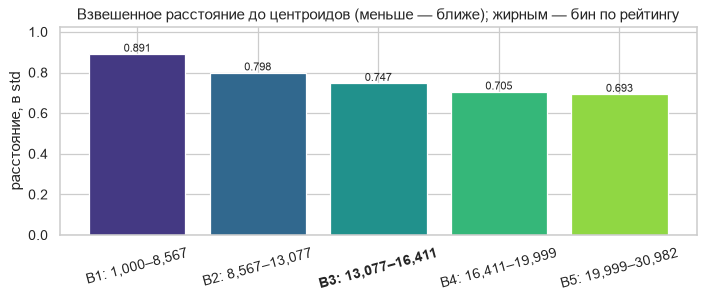

In [10]:
def bin_distances(X):
    """Взвешенное стандартизованное расстояние от строк X (игроки × признаки, NaN допустимы) до каждого центроида."""
    X = X[FEATURES]
    w_avail = X.notna().mul(WEIGHTS).sum(axis=1)
    return pd.DataFrame({b: np.sqrt((((X - c) / POOLED_STD) ** 2).mul(WEIGHTS).sum(axis=1, min_count=1) / w_avail)
                         for b, c in CENTROIDS.iterrows()})


ME = me_pm[FEATURES].mean()                      # признаки игрока, усреднённые по матчам
ME_MATCHES_OK = me_pm[FEATURES].notna().sum()    # в скольких матчах признак определён
dist_me = bin_distances(ME.to_frame().T).iloc[0]
BEHAV_BIN = int(dist_me.idxmin())
second = dist_me.drop(BEHAV_BIN).min()

print(f'Признаков определено у игрока: {ME.notna().sum()} из {len(FEATURES)}; '
      f'их суммарный вес: {WEIGHTS[ME.notna()].sum():.0%}')
print(f'Поведенческая оценка: {BIN_LABELS[BEHAV_BIN - 1]} (расстояние {dist_me.min():.3f}; '
      f'следующий бин — {second:.3f}, разница {second - dist_me.min():.3f} std)')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(BIN_LABELS, dist_me.values, color=[BIN_PALETTE[b] for b in dist_me.index])
for i, v in enumerate(dist_me.values):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
if RATING_BIN is not None:
    ax.get_xticklabels()[RATING_BIN - 1].set_fontweight('bold')
ax.set_ylim(0, dist_me.max() * 1.15)
ax.set_title('Взвешенное расстояние до центроидов (меньше — ближе); жирным — бин по рейтингу')
ax.set_ylabel('расстояние, в std'); ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

### 5.3 Насколько можно доверять поведенческой оценке

Прямая проверка: применяем тот же метод ко **всем** игрокам с рейтингом, у которых ≥ 2 матчей (как у нашего игрока),
усредняем их признаки по матчам и сравниваем поведенческий бин с бином по среднему рейтингу.
Случайный уровень считаем при тех же долях бинов (истинных и предсказанных), а для масштаба — та же оценка только по `nades_per_round`.

Оговорка: проверка внутривыборочная — центроиды построены по тем же парам с рейтингом, так что реальная точность на новых игроках
может быть только **ниже**.

Игроков в проверке: 3,141


Точное попадание в бин: 26.1% (случайный уровень 19.6%); ±1 бин: 54.3% (случайный уровень 45.4%)
Только по nades_per_round: точно 24.6%, ±1 бин 51.4%
Spearman(оценка, истинный бин) = 0.23
Куда метод относит игроков (доли): {'B1': '38%', 'B2': '10%', 'B3': '5%', 'B4': '12%', 'B5': '35%'}


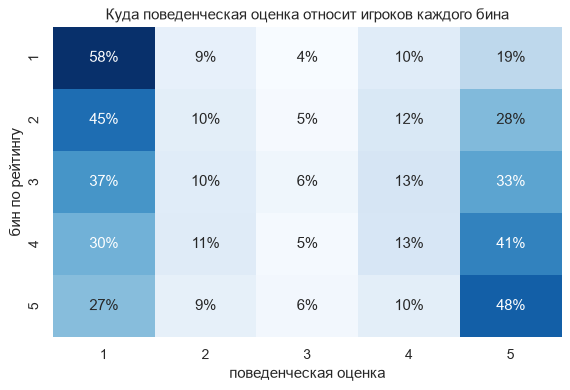

In [11]:
val_ids = multi.index[multi['rated_matches'] > 0]
val_pm = pm[pm.index.get_level_values('thrower_id').isin(val_ids)]
val = val_pm.groupby(level='thrower_id')[FEATURES].mean()
val_true = pd.cut(val_pm.groupby(level='thrower_id')['rating'].mean(), CUTS, labels=prof.index).astype(int)
val_pred = bin_distances(val).idxmin(axis=1).astype(int)
hit = (val_pred == val_true.reindex(val_pred.index))
near = ((val_pred - val_true.reindex(val_pred.index)).abs() <= 1)
VAL_EXACT, VAL_NEAR = hit.mean(), near.mean()
# случайный уровень при тех же долях бинов: P(true = i) · P(pred = j), просуммированное по нужным (i, j)
p_true = val_true.value_counts(normalize=True).reindex(prof.index, fill_value=0).values
p_pred = val_pred.value_counts(normalize=True).reindex(prof.index, fill_value=0).values
joint, ij = np.outer(p_true, p_pred), np.subtract.outer(prof.index.values, prof.index.values)
CHANCE_EXACT, CHANCE_NEAR = joint[ij == 0].sum(), joint[np.abs(ij) <= 1].sum()
# для сравнения: ближайший центроид только по nades_per_round
pred_npr = val['nades_per_round'].apply(lambda x: (CENTROIDS['nades_per_round'] - x).abs().idxmin())

print(f'Игроков в проверке: {len(val):,}')
print(f'Точное попадание в бин: {VAL_EXACT:.1%} (случайный уровень {CHANCE_EXACT:.1%}); '
      f'±1 бин: {VAL_NEAR:.1%} (случайный уровень {CHANCE_NEAR:.1%})')
print(f"Только по nades_per_round: точно {(pred_npr == val_true).mean():.1%}, ±1 бин {((pred_npr - val_true).abs() <= 1).mean():.1%}")
print(f"Spearman(оценка, истинный бин) = {val_pred.corr(val_true, method='spearman'):.2f}")
print('Куда метод относит игроков (доли):', {f'B{b}': f'{v:.0%}' for b, v in zip(prof.index, p_pred)})

conf = pd.crosstab(val_true.rename('бин по рейтингу'), val_pred.rename('поведенческая оценка'), normalize='index')
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(conf, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Куда поведенческая оценка относит игроков каждого бина')
plt.tight_layout(); plt.show()

**Вывод: поведенческая оценка бина — слабый сигнал.**
- Точное попадание — **26%** при случайном уровне 20%, ±1 бин — **54%** при 45%. Корреляция оценки с истинным бином (Spearman) — **0.23**.
  Лучше случайного угадывания, но для отдельного игрока это почти ничего не значит.
- Почти всю работу делает `nades_per_round`: только по нему точность уже 24.6%. Остальные 16 признаков добавляют около 1.5 п.п.
- **Метод тянет к краям.** Он относит 38% игроков к B1 и 35% к B5, а к B3 — только 5%. Причина в геометрии: центроиды лежат почти на одной прямой
  и близко друг к другу (размах `nades_per_round` — 0.39), а сами игроки разбросаны гораздо шире (std 0.64). Любой игрок заметно выше или ниже
  середины оказывается ближе всего к B5 или B1. Значит, оценка «B1» или «B5» для конкретного игрока **особенно ненадёжна**.

Поэтому дальше поведенческую оценку подаём только как «в районе Bx, неточно».

### 5.4 Итог по бину

Для сравнения в разделах 6–8 берём **референсный бин**: бин по рейтингу, если рейтинг известен (это факт, а не оценка),
иначе — поведенческую оценку.

In [12]:
REF_BIN = RATING_BIN if RATING_BIN is not None else BEHAV_BIN
REF_SRC = 'по рейтингу' if RATING_BIN is not None else 'поведенческая оценка'
if RATING_BIN is None:
    verdict = f'Рейтинга нет: бин только по поведению — {BIN_LABELS[BEHAV_BIN - 1]} (грубая оценка).'
elif RATING_BIN == BEHAV_BIN:
    verdict = f'Бин по рейтингу и поведенческая оценка совпали: {BIN_LABELS[RATING_BIN - 1]}.'
else:
    verdict = (f'Бин по рейтингу — {BIN_LABELS[RATING_BIN - 1]}, поведенческая оценка — {BIN_LABELS[BEHAV_BIN - 1]} '
               f'(расхождение на {abs(RATING_BIN - BEHAV_BIN)} бин(а)). По утилити игрок выглядит '
               f"{'как игрок более высокого' if BEHAV_BIN > RATING_BIN else 'как игрок более низкого'} бина.")
print(verdict)
print(f'Референсный бин для разделов 6–8: {BIN_LABELS[REF_BIN - 1]} ({REF_SRC})')

Бин по рейтингу — B3: 13,077–16,411, поведенческая оценка — B5: 19,999–30,982 (расхождение на 2 бин(а)). По утилити игрок выглядит как игрок более высокого бина.
Референсный бин для разделов 6–8: B3: 13,077–16,411 (по рейтингу)


## 6. Профиль игрока vs бин

Все 17 признаков: значение игрока (среднее по матчам), центроид и std референсного бина и **z** — на сколько объединённых
внутрибиновых std игрок отличается от центроида. Для масштаба рядом — сила разделения признака: если z = 0.5, а весь размах B1–B5
по этому признаку 0.1 std, то отклонение игрока в 5 раз больше разницы между крайними бинами, и оно говорит о его стиле, а не о рейтинге.

**std и 95% ДИ бина — ответы на разные вопросы.** `std` — разброс игроков-матчей внутри бина: «выходит ли значение игрока
за обычную разницу между игроками». `±95% ДИ` = 1.96·std/√n — точность самого центроида: «насколько точно известно среднее бина».
При тысячах пар в бине ДИ в 25–35 раз уже std, поэтому на графиках ниже он обычно меньше точки центроида. Вывод: центроиды бинов
известны точно, и неопределённость сравнения почти целиком на стороне игрока (2 матча, единицы бросков типа) и в перекрытии бинов,
а не в средних бинов. Поэтому отклонение игрока меряем в std, а не в ДИ: «игрок за пределами ДИ бина» верно почти для любого
игрока и ничего не значит.

«Надёжность»: **мало данных**, если у игрока < 20 бросков нужного типа за все матчи или признак определён только в одном матче.
Почему 20: у доли (например, пустых флешек) стандартная ошибка на n бросках ≈ `sqrt(p(1−p)/n)`; при n = 13 и p ≈ 0.5 это ~0.14,
то есть ~0.6 объединённого std — больше, чем весь размах B1–B5. Ниже ~20 бросков отклонение в 0.5–0.9 std неотличимо от шума.

In [13]:
FEAT_GT = {f: ('all' if f == 'nades_per_round' or f.startswith('share_') else
               'flash' if f.startswith('flash_') else 'he' if f.startswith('he_') else
               'molotov' if f.startswith('molotov_') else f.removeprefix('t_in_round_')) for f in FEATURES}
type_n = me_throws['grenade_type'].value_counts().reindex(GT_ORDER, fill_value=0)
type_n['all'] = len(me_throws)

cmp = pd.DataFrame({
    'игрок': ME,
    f'центроид B{REF_BIN}': CENTROIDS.loc[REF_BIN],
    f'std B{REF_BIN}': BIN_STD.loc[REF_BIN],
    f'±95% ДИ B{REF_BIN}': BIN_CI.loc[REF_BIN],
    'z (в объед. std)': (ME - CENTROIDS.loc[REF_BIN]) / POOLED_STD,
    'размах B1–B5 (в std)': SEPARATION,
    'матчей с признаком': ME_MATCHES_OK,
    'бросков типа': [type_n[FEAT_GT[f]] for f in FEATURES],
})
cmp['надёжность'] = np.where(cmp['игрок'].isna(), 'нет данных',
                             np.where((cmp['бросков типа'] < LOW_N_THROWS) | (cmp['матчей с признаком'] < 2), 'мало данных', 'ок'))
cmp.style.format({c: '{:.3f}' for c in cmp.columns[:6]}, na_rep='—').background_gradient(
    subset=['z (в объед. std)'], cmap='RdBu_r', vmin=-1.5, vmax=1.5)

,игрок,центроид B3,std B3,±95% ДИ B3,z (в объед. std),размах B1–B5 (в std),матчей с признаком,бросков типа,надёжность
nades_per_round,1.706,1.200,0.631,0.018,0.790,0.606,2,53,ок
share_smoke,0.294,0.318,0.161,0.005,-0.155,0.094,2,53,ок
share_flash,0.242,0.253,0.154,0.004,-0.070,0.041,2,53,ок
share_he,0.333,0.248,0.129,0.004,0.634,0.098,2,53,ок
share_molotov,0.131,0.180,0.112,0.003,-0.425,0.081,2,53,ок
flash_enemies_per_flash,0.800,0.755,0.392,0.013,0.117,0.244,2,13,мало данных
flash_team_per_flash,0.250,0.441,0.345,0.011,-0.562,0.204,2,13,мало данных
flash_empty_share,0.325,0.479,0.222,0.007,-0.710,0.268,2,13,мало данных
flash_kills_per100,6.250,4.634,9.101,0.299,0.173,0.158,2,13,мало данных
he_dmg_per_throw,14.462,13.633,11.389,0.362,0.072,0.195,2,17,мало данных


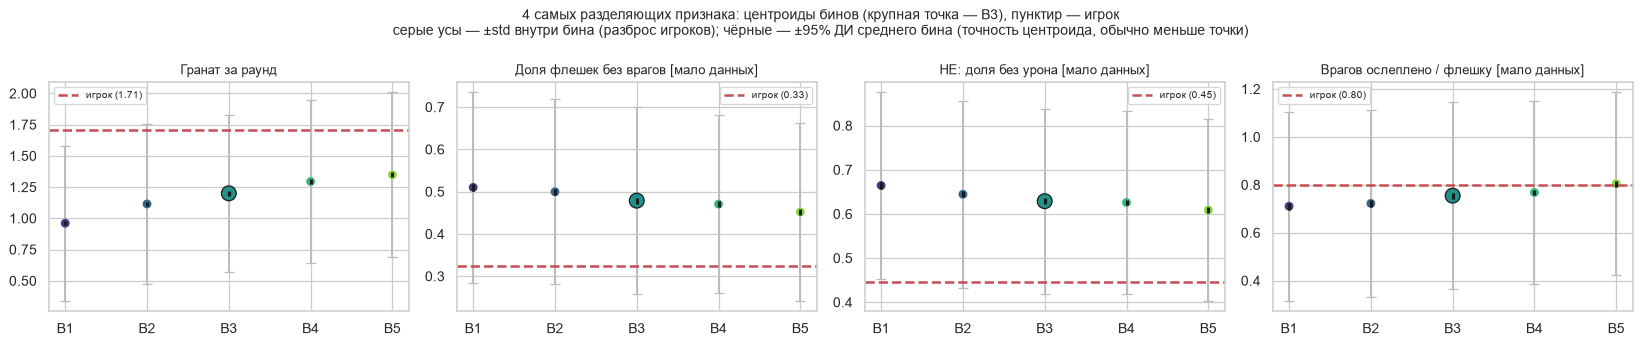

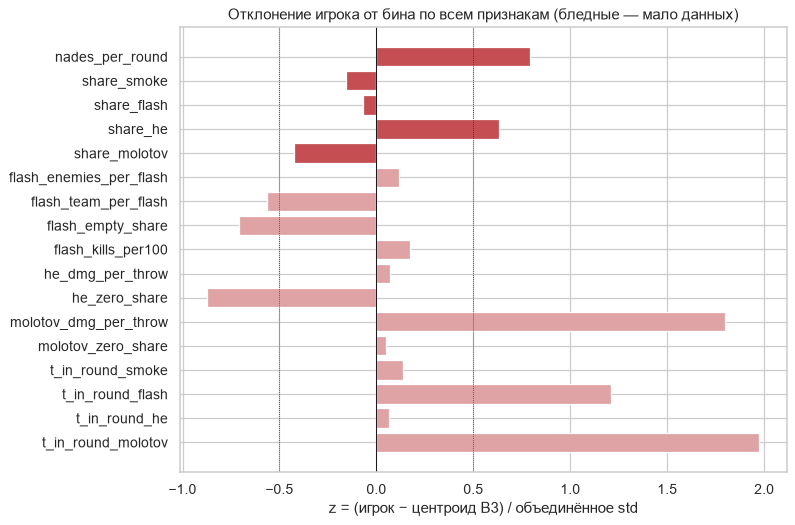

In [14]:
def plot_vs_bins(feats, titles, suptitle):
    """Центроиды 5 бинов: ± внутрибиновое std (серые усы) и ± 95% ДИ среднего (чёрные); игрок — горизонтальная линия."""
    fig, axes = plt.subplots(1, len(feats), figsize=(4.6 * len(feats), 3.9))
    for ax, f in zip(np.atleast_1d(axes), feats):
        x = np.arange(1, N_BINS + 1)
        ax.errorbar(x, CENTROIDS[f], yerr=BIN_STD[f], fmt='none', ecolor='#bbbbbb', capsize=4, zorder=1)
        ax.errorbar(x, CENTROIDS[f], yerr=BIN_CI[f], fmt='none', ecolor='k', elinewidth=2.5, capsize=0, zorder=3)
        ax.scatter(x, CENTROIDS[f], c=[BIN_PALETTE[b] for b in x], s=[140 if b == REF_BIN else 50 for b in x],
                   edgecolor=['k' if b == REF_BIN else 'none' for b in x], zorder=2)
        if pd.notna(ME[f]):
            ax.axhline(ME[f], color=PLAYER_COLOR, lw=2, ls='--', label=f'игрок ({ME[f]:.2f})')
            ax.legend(fontsize=8, loc='best')
        else:
            ax.text(0.5, 0.95, 'у игрока нет данных', transform=ax.transAxes, ha='center', va='top', color=PLAYER_COLOR)
        flag = '' if cmp.loc[f, 'надёжность'] == 'ок' else f" [{cmp.loc[f, 'надёжность']}]"
        ax.set_title(f'{titles.get(f, f)}{flag}', fontsize=10)
        ax.set_xticks(x, [f'B{b}' for b in x])
    fig.suptitle(f'{suptitle}\nсерые усы — ±std внутри бина (разброс игроков); чёрные — ±95% ДИ среднего бина '
                 '(точность центроида, обычно меньше точки)', fontsize=11)
    plt.tight_layout(); plt.show()


TITLES = {'nades_per_round': 'Гранат за раунд', 'flash_enemies_per_flash': 'Врагов ослеплено / флешку',
          'flash_team_per_flash': 'Тиммейтов ослеплено / флешку', 'flash_empty_share': 'Доля флешек без врагов',
          'flash_kills_per100': 'Flash-kill на 100 флешек', 'he_dmg_per_throw': 'HE: урон (HP+броня) / бросок',
          'he_zero_share': 'HE: доля без урона', 'molotov_dmg_per_throw': 'Молотов: урон / бросок',
          'molotov_zero_share': 'Молотов: доля без урона',
          **{f'share_{g}': f'Доля {g} в миксе' for g in GT_ORDER},
          **{f't_in_round_{g}': f'Тайминг {g}, с от 1-й гранаты' for g in GT_ORDER}}
KEY_FEATS = SEPARATION.sort_values(ascending=False).index[:4].tolist()
plot_vs_bins(KEY_FEATS, TITLES, f'4 самых разделяющих признака: центроиды бинов '
             f'(крупная точка — B{REF_BIN}), пунктир — игрок')

fig, ax = plt.subplots(figsize=(9, 6))
z = cmp['z (в объед. std)'].dropna().iloc[::-1]
ax.barh(z.index, z.values, color=[PLAYER_COLOR if cmp.loc[f, 'надёжность'] == 'ок' else '#e0a3a5' for f in z.index])
ax.axvline(0, color='k', lw=0.8)
for v in (-0.5, 0.5):
    ax.axvline(v, color='k', lw=0.6, ls=':')
ax.set_xlabel(f'z = (игрок − центроид B{REF_BIN}) / объединённое std'); ax.set_title('Отклонение игрока от бина по всем признакам (бледные — мало данных)')
plt.tight_layout(); plt.show()

**Расхождение в разделе 5 честно объясняется этой таблицей.** Рейтинг игрока (≈ 16k) — середина бина B3, а поведенческая оценка — B5
(B4 почти так же близко: 0.705 против 0.693). Расхождение создаёт в основном `nades_per_round`: 1.71 гранаты за раунд при 1.20 в B3
(z = +0.79). Это выше центроида даже B5, а именно у этого признака самый большой вес. Плюс к тому же сдвигают более редкие пустые флешки
и HE без урона (см. ниже). Учитывая раздел 5.3 (метод тянет к краям), это скорее «игрок много бросает», чем «игрок играет утилити как B5».

По отдельным признакам относительно B3:
- **Надёжно (53 броска):** гранат за раунд заметно больше нормы бина. Микс немного смещён в HE (33% против 25%) и от молотовов (13% против 18%),
  но по миксу бины не различаются, так что это про стиль, а не про рейтинг.
- **В сторону более высоких бинов, но мало данных:** пустых флешек 33% против 48% (z = −0.71), тиммейтов на флешку 0.25 против 0.44 (z = −0.56),
  HE без урона 45% против 63% (z = −0.87). На 13 флешках и 17 HE такие отклонения укладываются в шум (см. обоснование порога выше).
- **Большие z, которые ничего не значат:** урон молотова 10 HP против 2.5 (z = +1.8). Это 7 молотовов, весь урон набран в первом матче,
  и бины по этому признаку не различаются (размах 0.07 std). Тайминг флешек и молотовов — в разделе 8.

## 7. Разбор по типам утилити

Короткая версия разделов 5–8 `player_utility_analysis.ipynb`, но ориентир — **референсный бин**, а не весь датасет.
Для каждого типа — значение по каждому матчу (если тип прошёл порог `MIN_N`), среднее по матчам и центроид бина.
При двух матчах и единицах бросков любой вывод здесь — наблюдение, не диагноз.

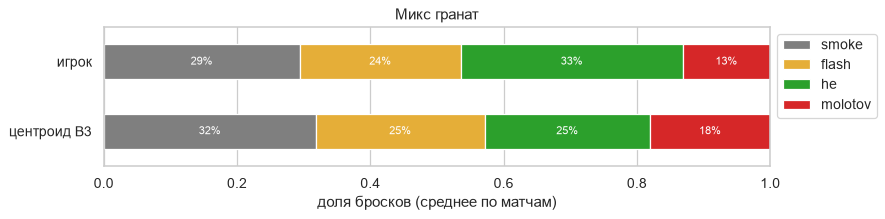

all: бросков по матчам [29, 24], всего 53 (порог за матч — 3)


,матч 1,матч 2,среднее игрока,центроид B3,z,надёжность
share_smoke,0.379,0.208,0.294,0.318,-0.155,ок
share_flash,0.276,0.208,0.242,0.253,-0.070,ок
share_he,0.207,0.458,0.333,0.248,0.634,ок
share_molotov,0.138,0.125,0.131,0.180,-0.425,ок


In [15]:
def per_type_table(feats, gt):
    t = me_pm[feats].T.copy()
    t.columns = [f'матч {i + 1}' for i in range(t.shape[1])]
    t['среднее игрока'] = ME[feats]
    t[f'центроид B{REF_BIN}'] = CENTROIDS.loc[REF_BIN, feats]
    t['z'] = cmp.loc[feats, 'z (в объед. std)']
    t['надёжность'] = cmp.loc[feats, 'надёжность']
    n_by_match = me_pm[f'n_{gt}'].astype(int).tolist() if gt != 'all' else me_pm['n_total'].astype(int).tolist()
    print(f"{gt}: бросков по матчам {n_by_match}, всего {type_n[gt]} (порог за матч — {MIN_N})")
    return t


fig, ax = plt.subplots(figsize=(10, 2.6))
mix = pd.DataFrame({'игрок': ME[MIX_FEATS].values, f'центроид B{REF_BIN}': CENTROIDS.loc[REF_BIN, MIX_FEATS].values},
                   index=GT_ORDER).T
mix.plot(kind='barh', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=ax)
for i, (_, row) in enumerate(mix.iterrows()):
    left = 0
    for g in GT_ORDER:
        ax.text(left + row[g] / 2, i, f'{row[g]:.0%}', ha='center', va='center', fontsize=9, color='white')
        left += row[g]
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('доля бросков (среднее по матчам)'); ax.set_title('Микс гранат')
ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
per_type_table(MIX_FEATS, 'all')

### 7.1 Флешки, HE, молотовы

In [16]:
display(per_type_table(FLASH_FEATS, 'flash'))
display(per_type_table(HE_FEATS, 'he'))
per_type_table(MOLOTOV_FEATS, 'molotov')

flash: бросков по матчам [8, 5], всего 13 (порог за матч — 3)


,матч 1,матч 2,среднее игрока,центроид B3,z,надёжность
flash_enemies_per_flash,1.000,0.600,0.800,0.755,0.117,мало данных
flash_team_per_flash,0.500,0.000,0.250,0.441,-0.562,мало данных
flash_empty_share,0.250,0.400,0.325,0.479,-0.710,мало данных
flash_kills_per100,12.500,0.000,6.250,4.634,0.173,мало данных


he: бросков по матчам [6, 11], всего 17 (порог за матч — 3)


,матч 1,матч 2,среднее игрока,центроид B3,z,надёжность
he_dmg_per_throw,23.833,5.091,14.462,13.633,0.072,мало данных
he_zero_share,0.167,0.727,0.447,0.629,-0.871,мало данных


molotov: бросков по матчам [4, 3], всего 7 (порог за матч — 3)


,матч 1,матч 2,среднее игрока,центроид B3,z,надёжность
molotov_dmg_per_throw,20.000,0.000,10.000,2.454,1.797,мало данных
molotov_zero_share,0.750,1.000,0.875,0.867,0.049,мало данных


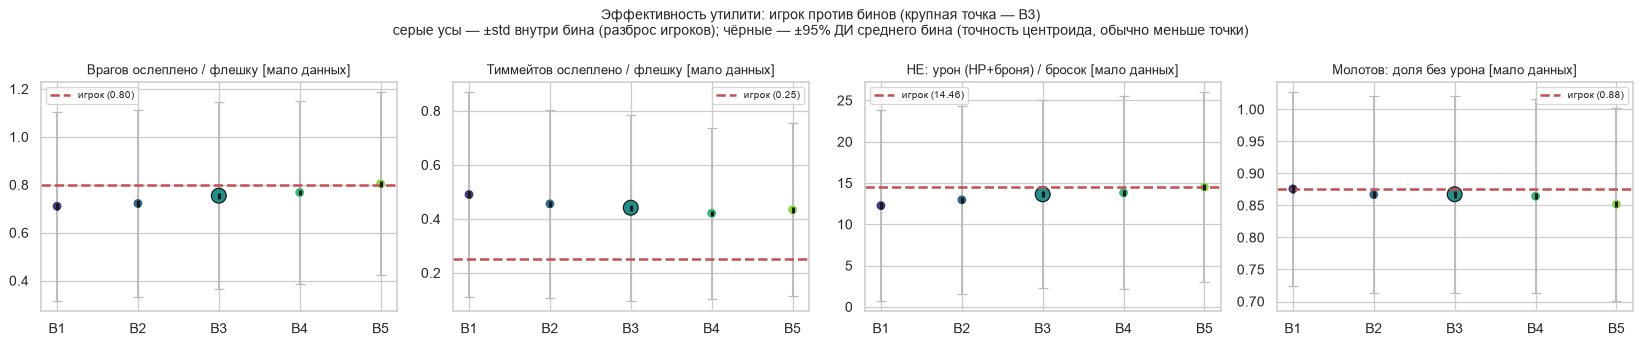

In [17]:
plot_vs_bins(['flash_enemies_per_flash', 'flash_team_per_flash', 'he_dmg_per_throw', 'molotov_zero_share'], TITLES,
             f'Эффективность утилити: игрок против бинов (крупная точка — B{REF_BIN})')

- **Микс** определён в обоих матчах, но матчи сильно отличаются: доля HE — 21% и 46%, смоков — 38% и 21%. Среднее (33% HE) держится
  на одном матче, поэтому «игрок любит HE» — пока гипотеза.
- **Флешки (13 штук):** в среднем лучше B3 по пустым флешкам и ослеплённым тиммейтам. Но разброс между матчами огромный:
  тиммейтов на флешку 0.50 в первом матче и 0.00 во втором, flash-kill — 12.5 и 0 на 100 (то есть одно убийство на 8 флешек).
- **HE (17 штук):** без урона 17% в первом матче и 73% во втором; урон за бросок 23.8 и 5.1 HP. Среднее (14.5 HP, 45% без урона)
  выглядит как у B5, но это среднее двух очень разных матчей.
  Кроме того, HE без урона — не обязательно плохой бросок: в зоне взрыва могло просто не быть врагов, а их позиций вне моментов урона
  в данных нет (оговорка ноутбука 1, раздел 6).
- **Молотовы (7 штук):** на пороге `MIN_N` в обоих матчах (4 и 3 броска). Доля без урона — как в бине (88% против 87%).
  Урон держится на одном-двух попаданиях, и действует оговорка ноутбука 1 про area denial.

**Итог раздела:** при 2 матчах разброс между матчами по каждому типу гранат больше, чем разница между B1 и B5.
Честный вывод по типам утилити — «ничего явно проблемного, есть 2–3 кандидата на проверку», а не диагноз.

## 8. Тайминг бросков по раунду

`t_in_round` — секунды от первой гранаты раунда (любого игрока) до броска; это прокси, а не время с начала раунда.
Признак игрока — среднее по матчам от среднего `t_in_round` его бросков типа (при ≥ `MIN_N` бросках), как в ноутбуке 1.
Напоминание из ноутбука 1: тайминг почти не различается между бинами, поэтому отклонение здесь — про стиль игрока, а не про рейтинг.

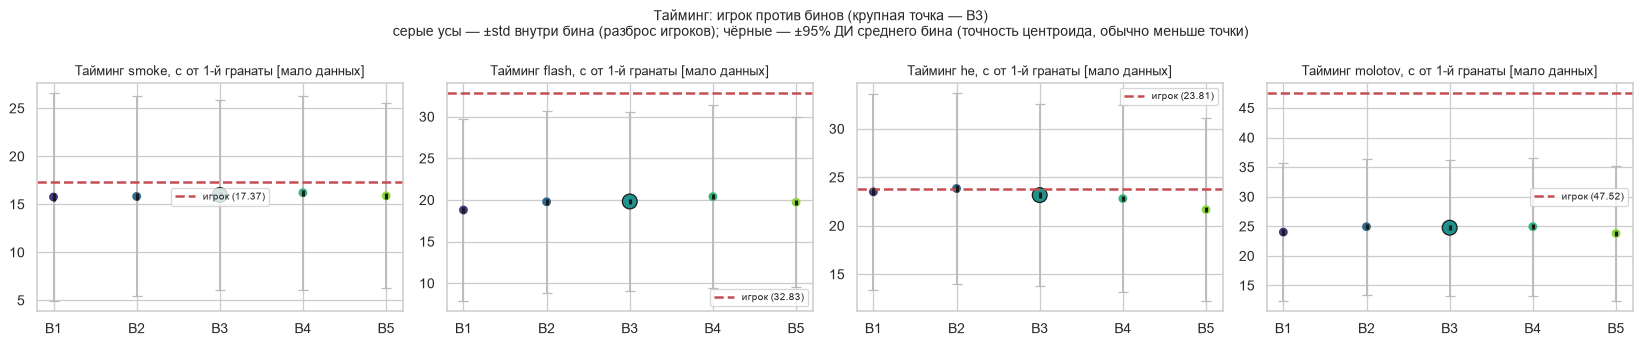

all: бросков по матчам [29, 24], всего 53 (порог за матч — 3)


,матч 1,матч 2,среднее игрока,центроид B3,z,надёжность,бросков типа,медиана по броскам игрока
t_in_round_smoke,14.871,19.869,17.370,15.972,0.138,мало данных,16,11.359
t_in_round_flash,27.805,37.859,32.832,19.823,1.210,мало данных,13,25.156
t_in_round_he,24.411,23.214,23.813,23.163,0.067,мало данных,17,14.281
t_in_round_molotov,34.387,60.651,47.519,24.766,1.974,мало данных,7,43.078


In [18]:
plot_vs_bins(TIMING_FEATS, TITLES,
             f'Тайминг: игрок против бинов (крупная точка — B{REF_BIN})')
timing = per_type_table(TIMING_FEATS, 'all')
timing['бросков типа'] = cmp.loc[TIMING_FEATS, 'бросков типа']
timing['медиана по броскам игрока'] = me_throws.groupby('grenade_type')['t_in_round'].median().reindex(GT_ORDER).values
timing

- **Смоки и HE — в такт с бином** (17.4 с против 16.0 и 23.8 с против 23.2).
- **Флешки и молотовы — заметно позже:** средний тайминг флешки 32.8 с против 19.8 в B3, молотова — 47.5 с против 24.8.
  Медианы ниже средних (25.2 и 43.1 с), то есть средние тянут несколько очень поздних бросков. По молотовам всего 7 бросков,
  а во втором матче среднее — 60.7 с.
- Тайминг между бинами почти не различается (ноутбук 1, раздел 8), поэтому это **про стиль, а не про рейтинг**. Возможно, игрок
  держит флешки и молотовы на позднюю фазу раунда: выход на плент, ретейк, пост-плант. Стороны (T/CT) и исходы раундов на 2 матчах
  разбирать не стали: выборка слишком маленькая.

## 9. Выводы для игрока

Сначала — подробности для аналитика (9.1–9.2): по каким правилам собираются рекомендации и что из них следует.
В самом конце (9.3) — тот же вывод для игрока простым языком, без бинов, z и прочих терминов.

### 9.1 Подробности для аналитика: правила рекомендаций

Рекомендации собираются автоматически из цифр выше. Правила, учитывающие слабое разделение бинов и маленькую выборку:
- **про бин** говорим только в осторожной форме: «по оценке, скорее всего в районе бина Bx» и с цифрой точности из раздела 5.3;
- признак считаем **заметным**, если игрок отклоняется от центроида референсного бина на **≥ 0.5 объединённого std** и надёжность «ок»;
  при «мало данных» — упоминаем только как кандидата на проверку. Порог — в std, а не в ДИ бина: центроиды известны точно
  (ДИ в 25–35 раз уже std), так что неточность рекомендаций идёт от малой выборки игрока и перекрытия бинов, а не от средних бинов;
- направление «как у более высоких / более низких бинов» берём из знака B5 − B1; признаки с размахом B1–B5 < 0.15 std
  (микс, тайминг смоков и т. п.) в рекомендации про рейтинг **не используем**: бины по ним не различаются;
- инструменты SCOPE.GG — из `docs/scope_gg_products_research.md`:
  **Grenade Predictor** (https://scope.gg/grenade-predictor) — лайнапы smoke/flash/HE/molotov на 2D-карте, видео, `setpos`, версии под 64/128 tick;
  **CS2 Dashboard → My Progress** (app.scope.gg) — тренд метрик за последние 30 матчей;
  **Demo Viewer** — 2D-повтор матча и разбор ошибок; **Comparing tool** — сравнение статистики с другим игроком.

In [19]:
Z_FLAG, MIN_SEP = 0.5, 0.15
n_m = len(me_pm)
recs, strengths, watch = [], [], []
found = {}  # сработавшие правила: ключ → (признак, надёжно ли, «как у более высоких бинов») — для отчёта в 9.3

# 1. бин — всегда с оговоркой
acc = (f'на проверке такой метод угадывает бин точно в {VAL_EXACT:.0%} случаев (случайно — {CHANCE_EXACT:.0%}) '
       f'и с точностью ±1 бин в {VAL_NEAR:.0%} (случайно — {CHANCE_NEAR:.0%}), а крайние бины B1 и B{N_BINS} он назначает слишком часто')
ties = [int(b) for b in dist_me.index if b != BEHAV_BIN and dist_me[b] - dist_me.min() < 0.05]
if ties:
    acc += f"; к тому же B{', B'.join(map(str, ties))} почти так же близко (разница < 0.05 std)"
if RATING_BIN is None:
    head = (f'По оценке, ты **скорее всего в районе бина B{BEHAV_BIN}** ({BIN_LABELS[BEHAV_BIN - 1].split(": ")[1]}). '
            f'Это неточно: рейтинга в твоих матчах нет, оценка сделана только по утилити, а бины по утилити сильно перекрываются ({acc}).')
elif RATING_BIN == BEHAV_BIN:
    head = (f'Твой средний рейтинг {MY_RATING:,.0f} — бин **B{RATING_BIN}**. По утилити ты тоже ближе всего к B{BEHAV_BIN} — '
            f'но это совпадение скорее ориентир, чем подтверждение ({acc}).')
else:
    head = (f'Твой средний рейтинг {MY_RATING:,.0f} — бин **B{RATING_BIN}**. По утилити ты, по грубой оценке, ближе к **B{BEHAV_BIN}** '
            f"(утилити {'«выше»' if BEHAV_BIN > RATING_BIN else '«ниже»'} твоего рейтинга). "
            f'Не переоценивай это расхождение: {acc}, и при 2 матчах одна игра может сдвинуть оценку.')


def note(f):
    return f"(z = {cmp.loc[f, 'z (в объед. std)']:+.2f}; бросков: {int(cmp.loc[f, 'бросков типа'])}, матчей: {int(cmp.loc[f, 'матчей с признаком'])} из {n_m})"


def towards_high(f):
    return np.sign(cmp.loc[f, 'z (в объед. std)']) * DIRECTION[f] > 0


TOOLS_LOW = {
    'nades_per_round': lambda: (f"**Мало утилити.** {ME['nades_per_round']:.2f} гранаты за раунд против {CENTROIDS.loc[REF_BIN, 'nades_per_round']:.2f} "
                                f"в B{REF_BIN} — это самый сильный признак, по которому бины различаются. Экономики в данных нет, поэтому сначала "
                                "проверь в **Demo Viewer**, были ли деньги на гранаты; если были — докупай утилити и следи за метрикой в "
                                f"**CS2 Dashboard → My Progress**. {note('nades_per_round')}"),
    'flash_enemies_per_flash': lambda: (f"**Флешки слепят мало врагов.** {ME['flash_enemies_per_flash']:.2f} врага на флешку против "
                                        f"{CENTROIDS.loc[REF_BIN, 'flash_enemies_per_flash']:.2f} в B{REF_BIN}; без врагов — {ME['flash_empty_share']:.0%} "
                                        f"(в бине {CENTROIDS.loc[REF_BIN, 'flash_empty_share']:.0%}). Возьми 2–3 флеш-лайнапа на Cache из **Grenade Predictor** "
                                        f"и в **Demo Viewer** проверь, где стояли враги в момент пустых флешек. {note('flash_enemies_per_flash')}"),
    'flash_team_per_flash': lambda: (f"**Флешки слепят тиммейтов.** {ME['flash_team_per_flash']:.2f} тиммейта на флешку против "
                                     f"{CENTROIDS.loc[REF_BIN, 'flash_team_per_flash']:.2f} в B{REF_BIN}. Найди такие раунды в **Demo Viewer** и замени эти броски "
                                     f"на поп-флешки из **Grenade Predictor**. {note('flash_team_per_flash')}"),
    'flash_kills_per100': lambda: (f"**Ослеплённых врагов редко добивают:** {ME['flash_kills_per100']:.1f} flash-kill на 100 флешек против "
                                   f"{CENTROIDS.loc[REF_BIN, 'flash_kills_per100']:.1f} в B{REF_BIN}. Это редкие события, на паре матчей разница может быть "
                                   f"случайной; посмотри в **Demo Viewer**, был ли рядом тиммейт, готовый пикнуть после флешки. {note('flash_kills_per100')}"),
    'he_dmg_per_throw': lambda: (f"**HE наносят мало урона.** {ME['he_dmg_per_throw']:.1f} HP+броня за бросок против "
                                 f"{CENTROIDS.loc[REF_BIN, 'he_dmg_per_throw']:.1f} в B{REF_BIN}, без урона {ME['he_zero_share']:.0%} "
                                 f"(в бине {CENTROIDS.loc[REF_BIN, 'he_zero_share']:.0%}). Попробуй стандартные HE-лайнапы из **Grenade Predictor** "
                                 f"на частые позиции врагов. {note('he_dmg_per_throw')}"),
    'molotov_dmg_per_throw': lambda: (f"**Молотовы реже задевают врага**, чем в B{REF_BIN}: без урона {ME['molotov_zero_share']:.0%} против "
                                      f"{CENTROIDS.loc[REF_BIN, 'molotov_zero_share']:.0%}. Часть таких молотовов могла честно закрыть проход, "
                                      f"поэтому сначала проверь в **Demo Viewer**, отступил ли враг. {note('molotov_dmg_per_throw')}"),
}
# пары признаков, которые описывают одно и то же: проверяем по любому из двух
GROUPS = {'flash_enemies_per_flash': ['flash_enemies_per_flash', 'flash_empty_share'],
          'he_dmg_per_throw': ['he_dmg_per_throw', 'he_zero_share'],
          'molotov_dmg_per_throw': ['molotov_dmg_per_throw', 'molotov_zero_share']}

for key, build in TOOLS_LOW.items():
    feats = [f for f in GROUPS.get(key, [key]) if SEPARATION[f] >= MIN_SEP and pd.notna(ME[f])]
    flagged = [f for f in feats if abs(cmp.loc[f, 'z (в объед. std)']) >= Z_FLAG]
    if not flagged:
        continue
    f = max(flagged, key=lambda f: abs(cmp.loc[f, 'z (в объед. std)']))
    reliable = cmp.loc[f, 'надёжность'] == 'ок'
    found[key] = (f, reliable, bool(towards_high(f)))
    if not towards_high(f):
        recs.append(build()) if reliable else watch.append('*(мало данных)* ' + build())
    elif reliable:
        strengths.append(f"{TITLES[f]}: {ME[f]:.2f} против {CENTROIDS.loc[REF_BIN, f]:.2f} в B{REF_BIN} — как у более высоких бинов {note(f)}")
    else:
        watch.append(f"{TITLES[f]}: {ME[f]:.2f} против {CENTROIDS.loc[REF_BIN, f]:.2f} в B{REF_BIN} — в сторону более высоких бинов, но данных мало {note(f)}")

# тайминг и микс: только как наблюдение о стиле
style = [f for f in MIX_FEATS + TIMING_FEATS if pd.notna(ME[f]) and abs(cmp.loc[f, 'z (в объед. std)']) >= Z_FLAG]
if style:
    watch.append('Стиль (по этим признакам бины не различаются, это не про рейтинг): ' + '; '.join(
        f"{TITLES[f]}: {ME[f]:.2f} против {CENTROIDS.loc[REF_BIN, f]:.2f} в B{REF_BIN} {note(f)}" for f in style))

recs.append(f"**Сыграй больше матчей, прежде чем делать выводы.** Сейчас всё посчитано по {n_m} матчам и {len(me_throws)} броскам. "
            "Отслеживай эти же метрики в **CS2 Dashboard → My Progress** (последние 30 матчей) — на 30 матчах и оценка бина, и отклонения станут надёжнее.")
recs.append("**Сравни себя с конкретным игроком.** Через **Comparing tool** сравни утилити-статистику с тиммейтом из своего стака "
            "с более высоким рейтингом — это точнее, чем сравнение с размытым средним по бину.")

text = head + '\n\n**Что можно улучшить:**\n\n' + '\n'.join(f'{i}. {r}' for i, r in enumerate(recs, 1))
if strengths:
    text += '\n\n**Что уже хорошо:** ' + '; '.join(strengths) + '.'
if watch:
    text += '\n\n**Кандидаты на проверку (мало данных или не про рейтинг):**\n\n' + '\n'.join(f'- {w}' for w in watch)
display(Markdown(text))

Твой средний рейтинг 15,980 — бин **B3**. По утилити ты, по грубой оценке, ближе к **B5** (утилити «выше» твоего рейтинга). Не переоценивай это расхождение: на проверке такой метод угадывает бин точно в 26% случаев (случайно — 20%) и с точностью ±1 бин в 54% (случайно — 45%), а крайние бины B1 и B5 он назначает слишком часто; к тому же B4 почти так же близко (разница < 0.05 std), и при 2 матчах одна игра может сдвинуть оценку.

**Что можно улучшить:**

1. **Сыграй больше матчей, прежде чем делать выводы.** Сейчас всё посчитано по 2 матчам и 53 броскам. Отслеживай эти же метрики в **CS2 Dashboard → My Progress** (последние 30 матчей) — на 30 матчах и оценка бина, и отклонения станут надёжнее.
2. **Сравни себя с конкретным игроком.** Через **Comparing tool** сравни утилити-статистику с тиммейтом из своего стака с более высоким рейтингом — это точнее, чем сравнение с размытым средним по бину.

**Что уже хорошо:** Гранат за раунд: 1.71 против 1.20 в B3 — как у более высоких бинов (z = +0.79; бросков: 53, матчей: 2 из 2).

**Кандидаты на проверку (мало данных или не про рейтинг):**

- Доля флешек без врагов: 0.33 против 0.48 в B3 — в сторону более высоких бинов, но данных мало (z = -0.71; бросков: 13, матчей: 2 из 2)
- Тиммейтов ослеплено / флешку: 0.25 против 0.44 в B3 — в сторону более высоких бинов, но данных мало (z = -0.56; бросков: 13, матчей: 2 из 2)
- HE: доля без урона: 0.45 против 0.63 в B3 — в сторону более высоких бинов, но данных мало (z = -0.87; бросков: 17, матчей: 2 из 2)
- Стиль (по этим признакам бины не различаются, это не про рейтинг): Доля he в миксе: 0.33 против 0.25 в B3 (z = +0.63; бросков: 53, матчей: 2 из 2); Тайминг flash, с от 1-й гранаты: 32.83 против 19.82 в B3 (z = +1.21; бросков: 13, матчей: 2 из 2); Тайминг molotov, с от 1-й гранаты: 47.52 против 24.77 в B3 (z = +1.97; бросков: 7, матчей: 2 из 2)

### 9.2 Итог для аналитика

Для **типичного** игрока (`25130446`: 2 матча, 53 гранаты, рейтинг ≈ 16k → бин **B3**):
1. **Бин.** По рейтингу — B3. Поведенческая оценка — «в районе B4–B5», но это **неточно**: метод угадывает бин в 26% случаев (случайно — 20%),
   тянет оценки к крайним бинам, а B4 и B5 для этого игрока почти равноудалены. Единственное, что за этим стоит надёжно: игрок
   **бросает больше утилити**, чем типичный игрок его бина (1.71 против 1.20 за раунд).
2. **Явных проблем по утилити на 2 матчах не видно.** Флешки и HE в среднем даже «в сторону более высоких бинов», но разброс между двумя матчами
   больше разницы между бинами. Это кандидаты на проверку, а не сильные стороны.
3. **Стиль:** поздние флешки и молотовы. Это не про рейтинг, но стоит посмотреть в Demo Viewer.

**Что этот ноутбук показывает про концепт «ты против своего бина».**
- Для рядового пользователя (2 матча) сравнение с бином — в первую очередь **контекст** («ты бросаешь больше, чем твой тир»),
  а не диагностика. Конкретные рекомендации по типам гранат требуют 20+ бросков типа, то есть ~5–10 матчей (как в CS2 Dashboard → My Progress).
- **Поведенческое отнесение к бину для игроков без рейтинга почти не работает:** по утилити бины перекрываются (раздел 2, 5.3).
  В продукте его стоит показывать только как подсказку с явной неточностью или не показывать вовсе, а для игроков с рейтингом брать бин по рейтингу.
- Ограничения датасета, не позволившие докрутить концепт: нет стрельбы, движения, экономики, исходов раундов и начала раунда; рейтинг есть
  только у 24% игроков-матчей; у типичного игрока в датасете 1–2 матча.

### 9.3 Отчёт для игрока

То, что увидел бы сам игрок: те же выводы, что в 9.1–9.2, но простыми словами.

In [20]:
LVL = 'у игроков твоего рейтинга' if RATING_BIN is not None else 'у игроков похожего уровня'
REF = CENTROIDS.loc[REF_BIN]
GT_RU = {'smoke': 'смоки', 'flash': 'флешки', 'he': 'HE', 'molotov': 'молотовы'}


def plural(n, one, few, many):
    n = abs(int(n))
    return one if n % 10 == 1 and n % 100 != 11 else few if 2 <= n % 10 <= 4 and not 12 <= n % 100 <= 14 else many


VS = {'nades_per_round': 'ты бросаешь {a:.1f} гранаты за раунд, а {lvl} обычно — {b:.1f}',
      'flash_empty_share': '{a:.0%} твоих флешек никого из врагов не ослепили, а {lvl} обычно — {b:.0%}',
      'flash_enemies_per_flash': 'твоя флешка в среднем слепит {a:.1f} врага, а {lvl} обычно — {b:.1f}',
      'flash_team_per_flash': 'твоя флешка в среднем слепит {a:.2f} тиммейта, а {lvl} обычно — {b:.2f}',
      'flash_kills_per100': 'на 100 твоих флешек приходится {a:.0f} убийств ослеплённых врагов, а {lvl} обычно — {b:.0f}',
      'he_dmg_per_throw': 'твоя HE в среднем наносит {a:.0f} урона, а {lvl} обычно — {b:.0f}',
      'he_zero_share': '{a:.0%} твоих HE не нанесли урона, а {lvl} обычно — {b:.0%}',
      'molotov_dmg_per_throw': 'твой молотов в среднем наносит {a:.0f} урона, а {lvl} обычно — {b:.0f}',
      'molotov_zero_share': '{a:.0%} твоих молотовов не нанесли урона, а {lvl} обычно — {b:.0%}'}
VS.update({f'share_{g}': f'доля «{GT_RU[g]}» среди твоих гранат — {{a:.0%}}, а {{lvl}} обычно — {{b:.0%}}' for g in GT_ORDER})
VS.update({f't_in_round_{g}': f'ты кидаешь {GT_RU[g]} в среднем через {{a:.0f}} с после первой гранаты в раунде, а {{lvl}} обычно — через {{b:.0f}} с'
           for g in GT_ORDER})


def vs(f):
    """Сравнение игрока с типичным игроком его уровня — одной фразой."""
    return VS[f].format(a=ME[f], b=REF[f], lvl=LVL)


def cap(s):
    return s[0].upper() + s[1:]


def rating_str(x):
    return f'{x:,.0f}'.replace(',', ' ')


# 1. Заслужен ли рейтинг — перевод сравнения «бин по рейтингу vs оценка по утилити» в слова
top = None
usable = [f for f in FEATURES if SEPARATION[f] >= MIN_SEP and pd.notna(ME[f])]
if RATING_BIN is None:
    lo, hi = prof.loc[BEHAV_BIN, ['rating_lo', 'rating_hi']]
    head = (f'В твоих матчах нет рейтинга, поэтому сказать, заслужен ли он, нельзя. По одним гранатам ты больше всего похож '
            f'на игроков с рейтингом примерно {rating_str(lo)}–{rating_str(hi)}, но это очень грубая прикидка.')
else:
    head = f'**Твой рейтинг (≈ {rating_str(MY_RATING)}) по тому, как ты используешь гранаты, выглядит заслуженным'
    gap = BEHAV_BIN - RATING_BIN
    if abs(gap) <= 1:
        head += ':** утилити ты играешь примерно так же, как другие игроки твоего уровня.'
    else:
        # какой признак сильнее всего «тянет» оценку от рейтинга к поведенческой
        pull = (WEIGHTS[usable] * (((ME[usable] - REF[usable]) / POOLED_STD[usable]) ** 2
                                   - ((ME[usable] - CENTROIDS.loc[BEHAV_BIN, usable]) / POOLED_STD[usable]) ** 2))
        top = pull.idxmax()
        if gap > 0:
            head += (':** по гранатам ты скорее похож на игроков с более высоким рейтингом, хотя разница в основном '
                     f'объясняется одним показателем: {vs(top)}.')
            if top == 'nades_per_round':
                head += (' То есть ты в первую очередь *больше* бросаешь — это не значит, что каждая граната у тебя работает лучше.')
        else:
            head = (f'**По гранатам ты пока немного не дотягиваешь до своего рейтинга (≈ {rating_str(MY_RATING)}):** утилити ты используешь '
                    'скорее как игроки с более низким рейтингом. Скорее всего, рейтинг ты зарабатываешь другим — стрельбой, позицией, '
                    f'решениями, — а гранаты сейчас твоя зона роста. Сильнее всего это видно здесь: {vs(top)}.')

# 2. Что делать / что уже хорошо — те же сработавшие правила из 9.1, но словами игрока и с теми же инструментами
TODO = {
    'nades_per_round': lambda: (f"**Бросай больше гранат:** {vs('nades_per_round')}. Сначала проверь в **Demo Viewer**, были ли деньги "
                                "на гранаты; если были — докупай утилити и следи за этой цифрой в **CS2 Dashboard → My Progress**."),
    'flash_enemies_per_flash': lambda: (f"**Флешки часто уходят в пустоту:** {vs('flash_empty_share')}. Возьми 2–3 флеш-лайнапа на Cache "
                                        "из **Grenade Predictor** и в **Demo Viewer** посмотри, где стояли враги в момент пустых флешек."),
    'flash_team_per_flash': lambda: (f"**Ты слепишь своих:** {vs('flash_team_per_flash')}. Найди такие раунды в **Demo Viewer** "
                                     "и замени эти броски на поп-флешки из **Grenade Predictor**."),
    'flash_kills_per100': lambda: (f"**Ослеплённых врагов редко добивают:** {vs('flash_kills_per100')}. Посмотри в **Demo Viewer**, "
                                   "был ли рядом тиммейт, готовый выйти сразу после флешки."),
    'he_dmg_per_throw': lambda: (f"**HE часто никого не задевают:** {vs('he_zero_share')}. Попробуй стандартные HE-лайнапы "
                                 "из **Grenade Predictor** на частые позиции врагов."),
    'molotov_dmg_per_throw': lambda: (f"**Молотовы редко задевают врага:** {vs('molotov_zero_share')}. Часть из них могла честно "
                                      "закрыть проход, поэтому сначала проверь в **Demo Viewer**, отступил ли враг."),
}
GOOD = {'nades_per_round': 'Ты активно пользуешься гранатами',
        'flash_enemies_per_flash': 'Твои флешки слепят больше врагов', 'flash_empty_share': 'Твои флешки реже уходят в пустоту',
        'flash_team_per_flash': 'Ты редко слепишь своих', 'flash_kills_per100': 'После твоих флешек врагов чаще добивают',
        'he_dmg_per_throw': 'Твои HE наносят больше урона', 'he_zero_share': 'Твои HE реже пролетают мимо',
        'molotov_dmg_per_throw': 'Твои молотовы чаще задевают врага', 'molotov_zero_share': 'Твои молотовы реже горят впустую'}

GT_GEN = {'flash': 'флешек', 'he': 'HE', 'molotov': 'молотовов', 'all': 'гранат'}
todo, good = [], []
for key, (f, reliable, high) in found.items():
    if high:
        if f == top:  # уже сказано в первой фразе
            continue
        few = '' if reliable else (f' Правда, ты покупаешь не так много {GT_GEN[FEAT_GT[f]]}, но это все равно '
                                   'хороший знак')
        good.append(f'{GOOD[f]}: {vs(f)}.{few}')
    else:
        todo.append(TODO[key]() + ('' if reliable else ' *(Пока мало бросков — сначала убедись, что это повторяется.)*'))

style_lines = []
for f in style:
    g = f.split('_')[-1]
    d = ME[f] - REF[f]
    if f.startswith('t_in_round_'):
        style_lines.append(f"Ты кидаешь {GT_RU[g]} заметно {'позже' if d > 0 else 'раньше'}, чем обычно — в среднем на {abs(d):.0f} с. "
                           'Это не ошибка, но пересмотри пару таких раундов в **Demo Viewer**: успевает ли граната к нужному моменту.')
    else:
        style_lines.append(f"Ты {'чаще' if d > 0 else 'реже'} других берёшь {GT_RU[g]}: {vs(f)}.")

n_t = len(me_throws)
todo.append('**Выучи точные лайнапы под карту, на которой играешь.** Даже если твои цифры сейчас не хуже, чем у игроков твоего уровня — это не значит, что каждый бросок был точным: 0 урона или пустая флешка выглядят так же, если врага просто не было рядом. '
            'В **Grenade Predictor** есть лайнапы смоков/флешек/HE/молотовых под конкретные точки Cache (с видео и setpos-координатами '
            'под твой тик-рейт) — заученный бросок почти всегда надёжнее броска "на глаз".')
todo.append(f"**Сыграй ещё несколько матчей и следи за динамикой.** Сейчас у нас всего {n_m} {plural(n_m, 'матч', 'матча', 'матчей')} "
            f"и {n_t} {plural(n_t, 'граната', 'гранаты', 'гранат')} — одна игра может всё сдвинуть. В **CS2 Dashboard → My Progress** "
            'видно, как меняются эти же цифры за последние 30 матчей.')
todo.append('**Сравни себя с тиммейтом посильнее.** В **Comparing tool** сравни свою статистику по гранатам с другом из стака, '
            'у которого рейтинг выше, — так сразу видно, что он делает иначе.')

report = head
if good:
    report += '\n\n**Что у тебя уже хорошо:**\n\n' + '\n'.join(f'- {g}' for g in good)
report += '\n\n**Что делать, чтобы стать лучше:**\n\n' + '\n'.join(f'{i}. {t}' for i, t in enumerate(todo, 1))
if style_lines:
    report += '\n\n**Твой стиль** (не хорошо и не плохо, просто особенность):\n\n' + '\n'.join(f'- {s}' for s in style_lines)
report += (f"\n\n*Насколько этому верить: оценка приблизительная. Она построена всего на {n_m} {plural(n_m, 'матче', 'матчах', 'матчах')} "
           'и смотрит только на гранаты — стрельба, экономика и решения в неё не входят. Даже на тысячах игроков угадать уровень '
           'по одним гранатам получается лишь чуть лучше, чем наугад, так что считай это подсказкой, а не приговором.*')
display(Markdown(report))

**Твой рейтинг (≈ 15 980) по тому, как ты используешь гранаты, выглядит заслуженным:** по гранатам ты скорее похож на игроков с более высоким рейтингом, хотя разница в основном объясняется одним показателем: ты бросаешь 1.7 гранаты за раунд, а у игроков твоего рейтинга обычно — 1.2. То есть ты в первую очередь *больше* бросаешь — это не значит, что каждая граната у тебя работает лучше.

**Что у тебя уже хорошо:**

- Твои флешки реже уходят в пустоту: 32% твоих флешек никого из врагов не ослепили, а у игроков твоего рейтинга обычно — 48%. Правда, ты покупаешь не так много флешек, но это все равно хороший знак
- Ты редко слепишь своих: твоя флешка в среднем слепит 0.25 тиммейта, а у игроков твоего рейтинга обычно — 0.44. Правда, ты покупаешь не так много флешек, но это все равно хороший знак
- Твои HE реже пролетают мимо: 45% твоих HE не нанесли урона, а у игроков твоего рейтинга обычно — 63%. Правда, ты покупаешь не так много HE, но это все равно хороший знак

**Что делать, чтобы стать лучше:**

1. **Выучи точные лайнапы под карту, на которой играешь.** Даже если твои цифры сейчас не хуже, чем у игроков твоего уровня — это не значит, что каждый бросок был точным: 0 урона или пустая флешка выглядят так же, если врага просто не было рядом. В **Grenade Predictor** есть лайнапы смоков/флешек/HE/молотовых под конкретные точки Cache (с видео и setpos-координатами под твой тик-рейт) — заученный бросок почти всегда надёжнее броска "на глаз".
2. **Сыграй ещё несколько матчей и следи за динамикой.** Сейчас у нас всего 2 матча и 53 гранаты — одна игра может всё сдвинуть. В **CS2 Dashboard → My Progress** видно, как меняются эти же цифры за последние 30 матчей.
3. **Сравни себя с тиммейтом посильнее.** В **Comparing tool** сравни свою статистику по гранатам с другом из стака, у которого рейтинг выше, — так сразу видно, что он делает иначе.

**Твой стиль** (не хорошо и не плохо, просто особенность):

- Ты чаще других берёшь HE: доля «HE» среди твоих гранат — 33%, а у игроков твоего рейтинга обычно — 25%.
- Ты кидаешь флешки заметно позже, чем обычно — в среднем на 13 с. Это не ошибка, но пересмотри пару таких раундов в **Demo Viewer**: успевает ли граната к нужному моменту.
- Ты кидаешь молотовы заметно позже, чем обычно — в среднем на 23 с. Это не ошибка, но пересмотри пару таких раундов в **Demo Viewer**: успевает ли граната к нужному моменту.

*Насколько этому верить: оценка приблизительная. Она построена всего на 2 матчах и смотрит только на гранаты — стрельба, экономика и решения в неё не входят. Даже на тысячах игроков угадать уровень по одним гранатам получается лишь чуть лучше, чем наугад, так что считай это подсказкой, а не приговором.*